
GRADIENT ANALYSIS
Variable: kernel
Gradient Norm: 0.031270195
Variable: recurrent_kernel
Gradient Norm: 0.11644451
Variable: bias
Gradient Norm: 0.051028244
Variable: kernel
Gradient Norm: 0.036758836
Variable: bias
Gradient Norm: 0.016639024


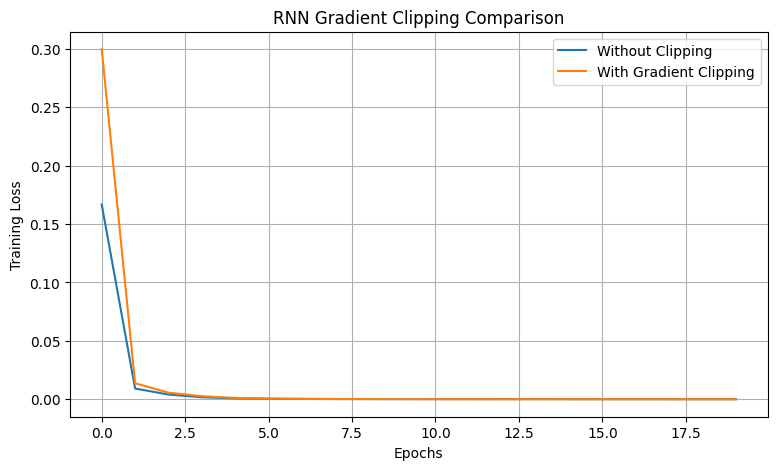

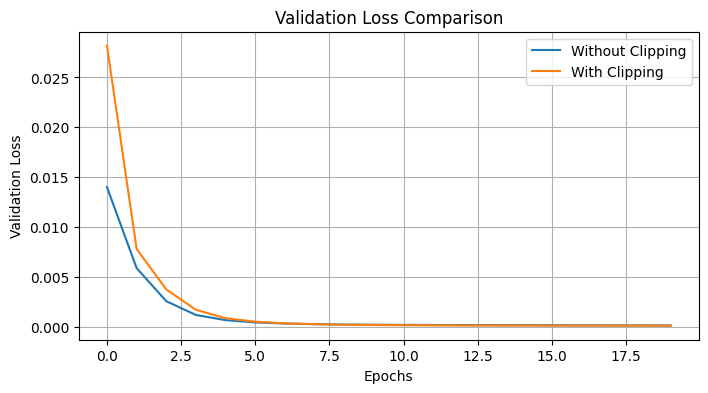


Gradient clipping experiment completed.


In [7]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

np.random.seed(42)
tf.random.set_seed(42)

# 1. Generate sequential dataset
data = np.sin(
    np.linspace(0, 100, 1000)
)

# 2. Create sequences
def create_sequences(data, steps):

    X, y = [], []

    for i in range(len(data) - steps):

        X.append(data[i:i + steps])

        y.append(data[i + steps])

    return np.array(X), np.array(y)

steps = 30

X, y = create_sequences(data, steps)

X = X.reshape(-1, steps, 1)

# 3. Define RNN model
def build_model():

    model = tf.keras.Sequential([

        tf.keras.layers.Input(shape=(steps, 1)),

        tf.keras.layers.SimpleRNN(
            32,
            activation="tanh"
        ),

        tf.keras.layers.Dense(1)
    ])

    return model

# 4. Create models
model_normal = build_model()

model_clipped = build_model()

# Use identical initial weights
initial_weights = model_normal.get_weights()

model_clipped.set_weights(initial_weights)

# 5. Compile normal model
model_normal.compile(
    optimizer=tf.keras.optimizers.SGD(
        learning_rate=0.01
    ),
    loss="mse"
)

# 6. Compile gradient-clipped model
clipped_optimizer = tf.keras.optimizers.SGD(
    learning_rate=0.01,
    clipnorm=1.0
)

model_clipped.compile(
    optimizer=clipped_optimizer,
    loss="mse"
)

# 7. Train normal RNN
history_normal = model_normal.fit(
    X,
    y,
    epochs=20,
    batch_size=32,
    validation_split=0.2,
    verbose=0
)

# 8. Train clipped RNN
history_clipped = model_clipped.fit(
    X,
    y,
    epochs=20,
    batch_size=32,
    validation_split=0.2,
    verbose=0
)

# 9. Calculate gradients
sample_x = tf.convert_to_tensor(
    X[:1],
    dtype=tf.float32
)

sample_y = tf.convert_to_tensor(
    y[:1].reshape(-1, 1),
    dtype=tf.float32
)

with tf.GradientTape() as tape:

    prediction = model_normal(sample_x)

    loss = tf.reduce_mean(
        tf.square(sample_y - prediction)
    )

gradients = tape.gradient(
    loss,
    model_normal.trainable_variables
)

print("\nGRADIENT ANALYSIS")

for variable, gradient in zip(
    model_normal.trainable_variables,
    gradients
):

    print("Variable:", variable.name)

    print("Gradient Norm:", tf.norm(gradient).numpy())

# 10. Display training loss comparison
plt.figure(figsize=(9, 5))

plt.plot(
    history_normal.history["loss"],
    label="Without Clipping"
)

plt.plot(
    history_clipped.history["loss"],
    label="With Gradient Clipping"
)

plt.xlabel("Epochs")
plt.ylabel("Training Loss")

plt.title("RNN Gradient Clipping Comparison")

plt.legend()
plt.grid()

plt.show()

# 11. Display validation loss
plt.figure(figsize=(8, 4))

plt.plot(
    history_normal.history["val_loss"],
    label="Without Clipping"
)

plt.plot(
    history_clipped.history["val_loss"],
    label="With Clipping"
)

plt.xlabel("Epochs")
plt.ylabel("Validation Loss")

plt.title("Validation Loss Comparison")

plt.legend()
plt.grid()

plt.show()

print("\nGradient clipping experiment completed.")